In [1]:
from sklearn.datasets import fetch_california_housing
import pandas as pd

housing = fetch_california_housing(as_frame=True)

df = housing.frame

C:\Users\Simrat Khalsa\anaconda3\Lib\site-packages\pandas\core\arrays\masked.py:56: UserWarning: Pandas requires version '1.4.2' or newer of 'bottleneck' (version '1.3.7' currently installed).
  from pandas.core import (


In [2]:
df.head()

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23,4.526
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22,3.585
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24,3.521
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25,3.413
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25,3.422


In [4]:
df.shape

(20640, 9)

#### Creating sample data 

In [5]:
df_sample = df.sample( n=5000,
                      random_state=42
                     )

In [6]:
df_sample.shape

(5000, 9)

In [7]:
df_sample.head()

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
20046,1.6812,25.0,4.192201,1.022284,1392.0,3.877437,36.06,-119.01,0.47700
3024,2.5313,30.0,5.039384,1.193493,1565.0,2.679795,35.14,-119.46,0.45800
15663,3.4801,52.0,3.977155,1.185877,1310.0,1.360332,37.80,-122.44,5.00001
20484,5.7376,17.0,6.163636,1.020202,1705.0,3.444444,34.28,-118.72,2.18600
9814,3.7250,34.0,5.492991,1.028037,1063.0,2.483645,36.62,-121.93,2.78000


In [8]:
# Understanding variable types
df_sample.info()

<class 'pandas.DataFrame'>
Index: 5000 entries, 20046 to 998
Data columns (total 9 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   MedInc       5000 non-null   float64
 1   HouseAge     5000 non-null   float64
 2   AveRooms     5000 non-null   float64
 3   AveBedrms    5000 non-null   float64
 4   Population   5000 non-null   float64
 5   AveOccup     5000 non-null   float64
 6   Latitude     5000 non-null   float64
 7   Longitude    5000 non-null   float64
 8   MedHouseVal  5000 non-null   float64
dtypes: float64(9)
memory usage: 390.6 KB


In [9]:
# Understanding the dataset (max, min etc.)
df_sample.describe()

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
count,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000
mean,3.847548,28.738600,5.415052,1.096529,1424.906200,2.964383,35.585798,-119.521650,2.059028
std,1.890851,12.530478,2.651202,0.574002,1108.469563,1.642381,2.140865,2.006263,1.148958
min,0.499900,1.000000,0.846154,0.500000,8.000000,1.263566,32.540000,-124.250000,0.149990
25%,2.553225,18.000000,4.416071,1.004559,784.000000,2.433980,33.930000,-121.742500,1.193750
50%,3.511400,29.000000,5.224950,1.047038,1163.500000,2.822057,34.220000,-118.470000,1.795000
75%,4.696700,37.000000,6.040717,1.097200,1721.250000,3.290997,37.692500,-117.990000,2.641750
max,15.000100,52.000000,132.533333,34.066667,16122.000000,83.171429,41.860000,-114.580000,5.000010


In [11]:
# Checking for missing values
df_sample.isnull().sum()

MedInc         0
HouseAge       0
AveRooms       0
AveBedrms      0
Population     0
AveOccup       0
Latitude       0
Longitude      0
MedHouseVal    0
dtype: int64

In [12]:
# Checking for duplicates
df_sample.duplicated().sum()

0

#### Exploration of Data
After checking for null values, duplicates and the datatypes, we can conclude that there is not major data-cleanup required for this dataset (as predicted since this is a scikit learn dataset).

In [13]:
# Check for the correlation between variables and potential outliers
df_sample.corr()["MedHouseVal"].sort_values(ascending=False)

MedHouseVal    1.000000
MedInc         0.685612
AveRooms       0.137468
HouseAge       0.111124
Population    -0.018881
Longitude     -0.043714
AveBedrms     -0.045040
AveOccup      -0.131088
Latitude      -0.149272
Name: MedHouseVal, dtype: float64

### Interpreting Correlation
From the results above we can see that Median House Value has the strongest correlation with Median Income with a correlation of .685612 points.

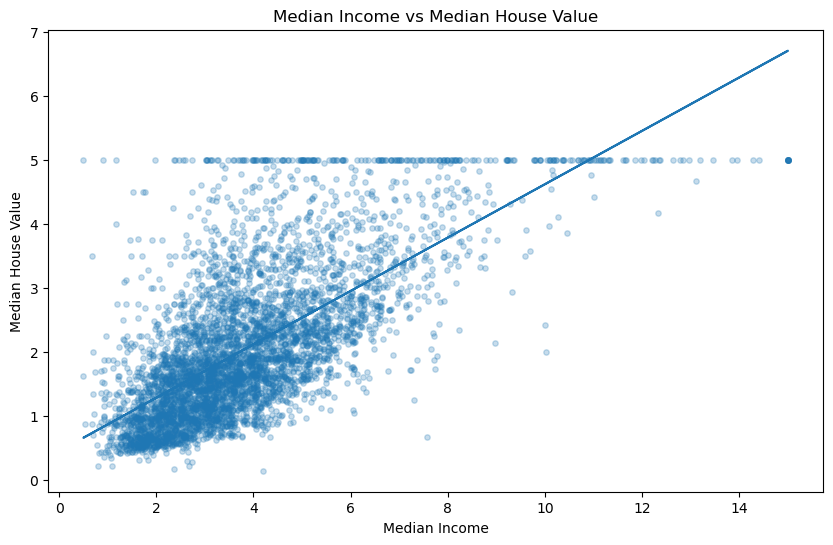

In [18]:
# Plot scatter plot for Median Income and Median HOuse Value, and add a best fit line.
import matplotlib.pyplot as plt
import numpy as np
a, b = np.polyfit(df_sample["MedInc"], df_sample["MedHouseVal"], 1)
plt.figure(figsize=(10, 6))
plt.scatter(df_sample["MedInc"], 
            df_sample["MedHouseVal"],
           alpha = 0.25,
           s=15)
plt.plot(df_sample["MedInc"], a*df_sample["MedInc"]+b)
plt.xlabel("Median Income")
plt.ylabel("Median House Value")
plt.title("Median Income vs Median House Value")
plt.show()

#### Observation
As Median House Value reaches 5, the points flatten out. It has hit a ceiling. 
This happened because the target variable was capped at 5, which corresponds to 500,000 in the orginial dataset's units. 

#### Interpretation from Plot
1. There is a positive relationship: as MedInc increases, MedHouseVal increases
2. The relationship isn't perfectly linear: values flatten at the upper end, target is capped.

### Simple Linear Regression 
To start off, we can do a simple regression using MedInc since it is the one that is most positively correlated with MedHouseVal.

In [20]:
X = df_sample[["MedInc"]]
y = df_sample["MedHouseVal"]

In [21]:
print(X.shape)
print(y.shape)

(5000, 1)
(5000,)


In [23]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(
    X,
    Y,
    test_size= 1000,
    random_state=42
)

In [24]:
print(X_train.shape)
print(X_test.shape)

(4000, 1)
(1000, 1)


In [27]:
from sklearn.linear_model import LinearRegression
model = LinearRegression()
model.fit(X_train, y_train)

LinearRegression()

In [31]:
y_pred = model.predict(X_test)

In [32]:
print(y_pred[:5])

[1.33888199 1.4655745  1.93391393 1.61958716 3.3058081 ]
